In [1]:
import kagglehub, pandas as pd, glob, os

path = kagglehub.dataset_download("hrishikeshb80/indian-handicraft-products")
root = os.path.join(path, "Handicraft_products")
df = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{root}/*.csv"))], ignore_index=True)
print(df.shape)

100%|██████████| 1.07G/1.07G [00:43<00:00, 26.3MB/s]

Extracting files...


(37273, 5)


In [2]:
import ast

def first(x):
    try:
        v = ast.literal_eval(x)
        return v[0] if v else None
    except Exception:
        return None

df['label'] = df['artform'].apply(first)
df['img']   = df['image_paths'].apply(first)
df = df.dropna(subset=['label', 'img']).copy()
df['label'] = df['label'].str.lower().str.strip()
df['img']   = df['img'].apply(lambda p: os.path.join(root, p))
df = df[df['img'].apply(os.path.exists)]

generic = {'fabart', 'handmade', 'plain solid'}
df = df[~df['label'].isin(generic)]
print(df['label'].value_counts().head(15))

label
ajrakh block printing             1744
sanganeri block printing          1604
bandhani tie dye                  1503
oxidised metal craft              1475
pochampally ikat weaving          1177
kalamkari block printing          1082
jacquard weaving                   908
batik block printing               877
bagru block printing               868
bagh block printing                746
patchwork                          724
bead work                          625
srikalahasti penwork kalamkari     618
wood carving                       607
hand knitted                       484
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

top = df['label'].value_counts().head(8).index
small = (df[df['label'].isin(top)]
         .sample(frac=1, random_state=42)
         .groupby('label').head(400)
         .reset_index(drop=True))

train, rest = train_test_split(small, test_size=0.3, stratify=small['label'], random_state=42)
val, test   = train_test_split(rest, test_size=0.5, stratify=rest['label'], random_state=42)
print(len(train), len(val), len(test))
print(small['label'].value_counts())

2240 480 480
label
bandhani tie dye            400
batik block printing        400
jacquard weaving            400
ajrakh block printing       400
kalamkari block printing    400
sanganeri block printing    400
pochampally ikat weaving    400
oxidised metal craft        400
Name: count, dtype: int64


In [4]:
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
classes = sorted(small['label'].unique())
c2i = {c: i for i, c in enumerate(classes)}
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                               transforms.ColorJitter(0.2, 0.2), transforms.ToTensor(), norm])
tf_eval  = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.tf = d['img'].tolist(), tf
        self.y = [c2i[l] for l in d['label']]
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert('RGB')), self.y[i]

dl_train = DataLoader(DS(train, tf_train), batch_size=32, shuffle=True, num_workers=2)
dl_val   = DataLoader(DS(val, tf_eval), batch_size=32, num_workers=2)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters(): p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
hist = {'train_loss': [], 'val_acc': []}

for epoch in range(6):
    model.train(); tot = 0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
        tot += loss.item() * len(y)
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in dl_val:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    hist['train_loss'].append(tot / len(train)); hist['val_acc'].append(correct / len(val))
    print(f"epoch {epoch+1}: loss {hist['train_loss'][-1]:.3f}  val acc {hist['val_acc'][-1]:.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 53.0MB/s]


epoch 1: loss 1.731  val acc 0.546
epoch 2: loss 1.274  val acc 0.619
epoch 3: loss 1.081  val acc 0.671
epoch 4: loss 0.992  val acc 0.671
epoch 5: loss 0.904  val acc 0.692
epoch 6: loss 0.869  val acc 0.721


In [5]:
for p in model.layer4.parameters(): p.requires_grad = True

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(),     'lr': 1e-3},
])

for epoch in range(8):
    model.train(); tot = 0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
        tot += loss.item() * len(y)
    model.eval(); correct = 0
    with torch.no_grad():
        for x, y in dl_val:
            correct += (model(x.to(device)).argmax(1).cpu() == y).sum().item()
    hist['train_loss'].append(tot / len(train)); hist['val_acc'].append(correct / len(val))
    print(f"epoch {epoch+1}: loss {hist['train_loss'][-1]:.3f}  val acc {hist['val_acc'][-1]:.3f}")

epoch 1: loss 0.744  val acc 0.808
epoch 2: loss 0.361  val acc 0.863
epoch 3: loss 0.188  val acc 0.856
epoch 4: loss 0.117  val acc 0.852
epoch 5: loss 0.076  val acc 0.852
epoch 6: loss 0.053  val acc 0.838
epoch 7: loss 0.040  val acc 0.860
epoch 8: loss 0.046  val acc 0.856


                          precision    recall  f1-score   support

   ajrakh block printing       0.79      0.80      0.79        60
        bandhani tie dye       0.95      0.95      0.95        60
    batik block printing       0.92      0.75      0.83        60
        jacquard weaving       0.92      0.80      0.86        60
kalamkari block printing       0.80      0.98      0.88        60
    oxidised metal craft       0.97      1.00      0.98        60
pochampally ikat weaving       0.84      0.90      0.87        60
sanganeri block printing       0.76      0.73      0.75        60

                accuracy                           0.86       480
               macro avg       0.87      0.86      0.86       480
            weighted avg       0.87      0.86      0.86       480



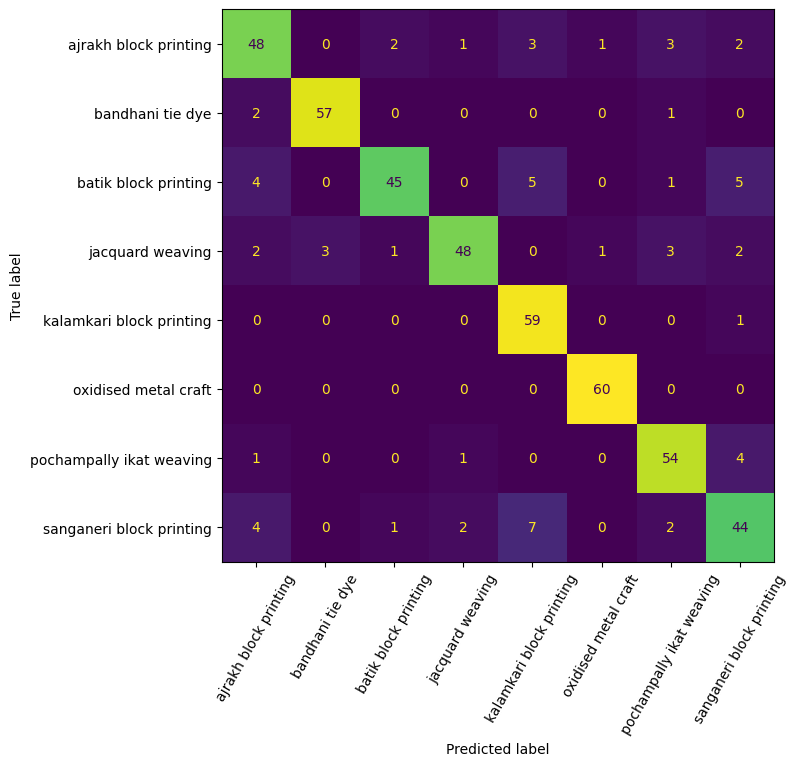

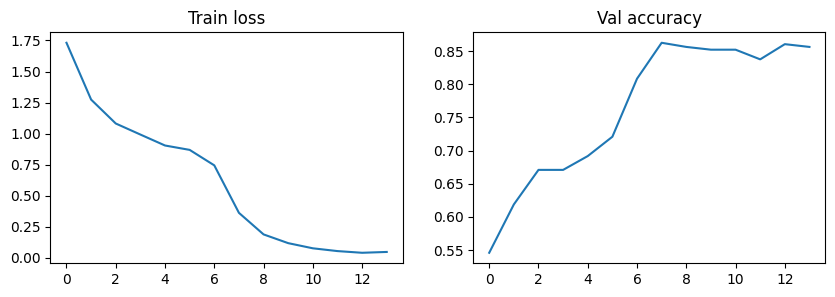

In [6]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

dl_test = DataLoader(DS(test, tf_eval), batch_size=32, num_workers=2)
model.eval(); preds, ys = [], []
with torch.no_grad():
    for x, y in dl_test:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); ys += y.tolist()

print(classification_report(ys, preds, target_names=classes))
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(ys, preds), display_labels=classes).plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout(); plt.show()

fig, a = plt.subplots(1, 2, figsize=(10, 3))
a[0].plot(hist['train_loss']); a[0].set_title('Train loss')
a[1].plot(hist['val_acc']);    a[1].set_title('Val accuracy')
plt.show()

In [7]:
torch.save({'state': model.state_dict(), 'classes': classes}, 'craft_resnet18.pt')

In [8]:
!pip -q install gradio
import gradio as gr

INFO = {
 'ajrakh block printing': ("Ajrakh", "Resist-printed with wooden blocks in indigo and madder red, with dense geometric patterns, traditionally from Sindh and Kutch."),
 'bandhani tie dye': ("Bandhani", "Tie-dye textile where tiny knots are bound before dyeing to form dotted patterns, from Gujarat and Rajasthan."),
 'batik block printing': ("Batik", "Wax-resist dyed fabric with block-printed or hand-drawn motifs."),
 'jacquard weaving': ("Jacquard Weave", "Woven fabric with intricate patterns built into the weave using a jacquard loom."),
 'kalamkari block printing': ("Kalamkari", "Block-printed or hand-painted cloth with natural dyes, known for detailed floral and mythological motifs."),
 'oxidised metal craft': ("Oxidised Metal Craft", "Metalwork with a darkened antique finish that highlights engraved detail."),
 'pochampally ikat weaving': ("Pochampally Ikat", "Handwoven fabric made from pre-dyed yarn, giving the signature geometric patterns of Telangana."),
 'sanganeri block printing': ("Sanganeri Print", "Fine floral block prints on a light base, from Sanganer, Rajasthan."),
}

model.eval()
def predict(img):
    x = tf_eval(img.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0].cpu()
    top = p.argmax().item(); label = classes[top]
    name, desc = INFO[label]
    card = f"## {name}\n**Category:** Handicraft / {label.title()}\n\n**Description:** {desc}\n\n**Tags:** handmade, indian craft, {label.split()[0]}\n\n_Confidence: {p[top]:.0%}_"
    return {classes[i]: float(p[i]) for i in range(len(classes))}, card

gr.Interface(predict, gr.Image(type='pil'),
             [gr.Label(num_top_classes=3), gr.Markdown()],
             title="Craft Cataloger").launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2d3b28595207baa192.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
!pip -q install openai-whisper
import whisper
asr = whisper.load_model("base")
def transcribe(audio_path):
    return asr.transcribe(audio_path)["text"]

gr.Interface(transcribe, gr.Audio(type='filepath'), "text", title="Artisan Voice Note").launch(share=True)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


100%|███████████████████████████████████████| 139M/139M [00:01<00:00, 75.8MiB/s]


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://52e05c7d781ab7fe60.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
